# Phase 1 — Dataset Audit (SciFact)
Thin viewer over artifacts produced by `scripts/prepare_data.py` and `scripts/inspect_dataset.py`.
No model is trained here. Run those scripts first.

In [1]:
import sys, json
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "base.yaml").is_file())
sys.path.insert(0, str(root))
from src.config import load_config
from src.data_io import read_jsonl, read_qrels
from src.utils import read_json
cfg = load_config(root=root)
proc, reports = cfg["_abs"]["processed_dir"], cfg["_abs"]["reports_dir"]
audit = read_json(reports / "data_audit.json")
print("Audit status:", audit["status"], "| seed:", audit["seed"])

Audit status: PASS | seed: 42


## 1. Raw file integrity (SHA-256)

In [2]:
pd.Series(audit["raw_file_sha256"], name="sha256").to_frame()

,sha256
corpus,dec31c8182f3d744c7d2c09423756fd1d17cbef75808db...
queries,8ff84a7c903f722981cd8d595c022660140c51867b2760...
test_qrels,0864bb985e0ca2367ba217977e72004d549054b2b06666...
train_qrels,a53f2114831916c096b6c37d9e54da68cef4efdcdbd5ed...


## 2. Counts and reconciliation

In [3]:
pd.Series(audit["reconciliation"], name="value").to_frame()

,value
official_test_queries,300
official_train_queries,809
queries_jsonl_total,1109
queries_without_any_qrel,0
split_queries_sum_equals_official_train_queries,True
split_rows_sum_equals_official_train_rows,True
split_train_queries,647
split_train_rows,742
split_val_queries,162
split_val_rows,177


## 3. Leakage gates (all must be True)

In [4]:
pd.Series(audit["leakage_gates"], name="passed").to_frame()

,passed
no_query_straddles_partitions,True
train_rows_only_train_queries,True
train_test_disjoint,True
train_val_disjoint,True
val_rows_only_val_queries,True
val_test_disjoint,True


## 4. Text length statistics (whitespace words)
Encoder truncation (256 wordpieces) will be measured with the real tokenizer in Phase 2; here is only a heuristic.

In [5]:
rows = {"abstract_words": audit["corpus"]["abstract_words"], "title_words": audit["corpus"]["title_words"],
        "query_words": audit["queries"]["query_words"]}
display(pd.DataFrame(rows).T)
print(audit["truncation_heuristic"])

,max,mean,median,min,p95
abstract_words,1524.0,201.81,192.0,26.0,341.0
title_words,40.0,12.82,12.0,1.0,21.0
query_words,39.0,12.38,12.0,3.0,21.0


{'caveat': 'Whitespace-word heuristic only; exact truncation will be measured with the MiniLM tokenizer in Phase 2. No text is truncated in the processed files.', 'docs_exceeding_heuristic_budget': 2927, 'fraction': 0.5647, 'heuristic_word_budget': 190, 'max_seq_length_wordpieces': 256}


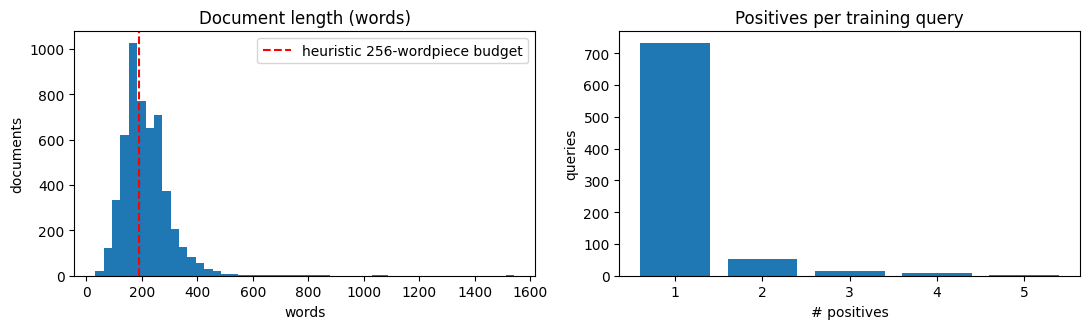

In [6]:
docs = read_jsonl(proc / "corpus_processed.jsonl")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist([len(d["doc_text"].split()) for d in docs], bins=50)
ax[0].axvline(cfg["preprocess"]["approx_words_per_wordpiece_budget"], color="r", ls="--", label="heuristic 256-wordpiece budget")
ax[0].set(title="Document length (words)", xlabel="words", ylabel="documents"); ax[0].legend()
h = audit["train_qrels_official"]["positives_per_query_histogram"]
ax[1].bar(list(h.keys()), list(h.values())); ax[1].set(title="Positives per training query", xlabel="# positives", ylabel="queries")
plt.tight_layout(); plt.show()

## 5. Official qrels vs. derived split

In [7]:
summary = pd.DataFrame({
    "queries": [audit["reconciliation"]["split_train_queries"], audit["reconciliation"]["split_val_queries"], audit["reconciliation"]["official_test_queries"]],
    "positive_rows": [audit["reconciliation"]["split_train_rows"], audit["reconciliation"]["split_val_rows"], audit["test_qrels_official"]["n_rows"]],
}, index=["train (80%)", "validation (20%)", "test (reserved)"])
summary

,queries,positive_rows
train (80%),647,742
validation (20%),162,177
test (reserved),300,339


## 6. Query metadata is NOT a relevance label
`SUPPORT` / `CONTRADICT` annotations describe claim verification, not retrieval relevance (info only).

In [8]:
audit["queries"]["metadata_annotation_label_counts_INFO_ONLY"]

{'CONTRADICT': 463, 'SUPPORT': 832}

## 7. Sample lexical searches (TF-IDF, training queries only)
A training-free sanity probe — **not** the project baseline and not a reported metric. `*` marks a judged positive.

In [9]:
samples = read_json(reports / "sample_searches.json")["samples"]
for s in samples:
    print(f"Query {s['query_id']}: {s['query']}")
    for h in s["top_k"]:
        print(f"  {'*' if h['corpus_id'] in s['positives'] else ' '} #{h['rank']} [{h['corpus_id']}] {h['score']:.3f} {h['title'][:75]}")
    print()

Query 689: Less than 10% of patients exposed to radiation have activated markers of mesenchymal stem cells.
    #1 [18953920] 0.221 The Epithelial-Mesenchymal Transition Generates Cells with Properties of St
    #2 [25238950] 0.174 FGF-2 enhances intestinal stem cell survival and its expression is induced 
    #3 [31293581] 0.154 Ionizing radiation-induced long-term expression of senescence markers in mi
    #4 [24766509] 0.153 Differentiation of mesenchymal stem cells and embryonic stem cells into ste
    #5 [3863543] 0.150 Mesenchymal Inflammation Drives Genotoxic Stress in Hematopoietic Stem Cell

Query 293: Crossover hot spots are found within gene promoters in Saccharomyces cerevisiae.
  * #1 [10874408] 0.164 Mapping Meiotic Single-Strand DNA Reveals a New Landscape of DNA Double-Str
    #2 [32638085] 0.153 Histone acetylation and deacetylation in yeast
    #3 [13949015] 0.131 LINE-1 Retrotransposition Activity in Human Genomes
    #4 [21170174] 0.130 Crossover and noncrossover pa

## 8. Caveats
- Qrels are positive-only and sparse; unjudged documents are *unlabeled*, not confirmed negatives.
- The corpus is shared across train/val/test (shared-corpus benchmark).
- `test.tsv` is reserved for one final evaluation in Phase 5.